# **Loss Function in Logistic Regression:**

## 1. Introduction:

A Cost Function provides a way to measure how well a specific set of model parameters fits the training data.

It helps us evaluate the model and choose better parameters (weights and bias).

In Logistic Regression, the objective is to find the values of $\vec{w}$ and $b$ that minimize the overall cost.

Recall the Logistic Regression model:

$$
\boxed{
f_{\vec{w},b}(\vec{x})=
\frac{1}{1+e^{-(\vec{w}\cdot\vec{x}+b)}}
}
$$

The model produces a probability between 0 and 1.

In binary classification:

- $y=1$ represents the positive class.
- $y=0$ represents the negative class.

The main objective is to choose suitable parameters that make the predicted probabilities close to the actual class labels.

## 2. Training Dataset Notation:

Consider a binary classification dataset containing information about patients and their tumor diagnoses.

We use:

- $m$ = Total number of training examples.
- $n$ = Total number of features.
- $x_1,x_2,\ldots,x_n$ = Input features.
- $y$ = Actual class label (either 0 or 1).
- $\vec{w}$ = Weight vector.
- $b$ = Bias.
- $f_{\vec{w},b}(\vec{x})$ = Predicted probability.

Each training example contains a feature vector and its corresponding actual label.

$$
\left(\vec{x}^{(i)},y^{(i)}\right)
$$

Where $i$ represents the training example number.

The actual label can only be:

$$
y^{(i)}\in\{0,1\}
$$

## 3. Squared Error Cost Function:

Recall the Squared Error Cost Function from Linear Regression.

For one training example, the loss is:

$$
\boxed{
L(f(x),y)=\frac{1}{2}(f(x)-y)^2
}
$$

For the complete training dataset, the cost function is:

$$
\boxed{
J(\vec{w},b)=
\frac{1}{2m}
\sum_{i=1}^{m}
\left(
f_{\vec{w},b}(\vec{x}^{(i)})-y^{(i)}
\right)^2
}
$$

The factor $\frac{1}{2}$ is included to simplify differentiation.

The cost function measures the average squared prediction error across all training examples.

### Squared Error with Linear Regression:

In Linear Regression, the prediction function is:

$$
f_{\vec{w},b}(\vec{x})=
\vec{w}\cdot\vec{x}+b
$$

When combined with the Squared Error Cost Function, the cost function is convex.

A convex function has the property that any local minimum is also a global minimum.

This makes Gradient Descent suitable for minimizing the Linear Regression cost function.

## 4. Why Is Squared Error Not Suitable for Logistic Regression?

In Logistic Regression, the prediction function is different because it uses the Sigmoid Function.

Recall:

$$
f_{\vec{w},b}(\vec{x})=
\frac{1}{1+e^{-(\vec{w}\cdot\vec{x}+b)}}
$$

We could try using the same Squared Error Cost Function:

$$
J(\vec{w},b)=
\frac{1}{2m}
\sum_{i=1}^{m}
\left(
f_{\vec{w},b}(\vec{x}^{(i)})-y^{(i)}
\right)^2
$$

However, when the sigmoid prediction function is combined with squared error, the resulting cost function can become non-convex with respect to the model parameters.

### What Is a Non-Convex Cost Function?

A non-convex cost function can contain multiple local minima.

Gradient Descent may get stuck in a local minimum instead of reaching the global minimum.

### Comparison:

| Squared Error with Linear Regression | Squared Error with Logistic Regression |
|---|---|
| Produces a convex cost function. | Can produce a non-convex cost function. |
| Has no separate local minima. | Can have multiple local minima. |
| Suitable for Linear Regression. | Not the preferred choice for Logistic Regression. |

Therefore, we need a different Loss Function for Logistic Regression.

## 5. Loss Function vs Cost Function:

Before introducing Logistic Loss, it is important to understand the difference between Loss and Cost.

### Loss Function:

A Loss Function measures how wrong the model's prediction is for one individual training example.

It depends on:

- Predicted probability $f(x)$.
- Actual label $y$.

It is represented by:

$$
L(f(x),y)
$$

### Cost Function:

A Cost Function measures the average loss across the entire training dataset.

It is represented by:

$$
J(\vec{w},b)
$$

The relationship is:

$$
\boxed{
\text{Cost Function}=
\text{Average of Individual Losses}
}
$$

In mathematical form:

$$
\boxed{
J(\vec{w},b)=
\frac{1}{m}
\sum_{i=1}^{m}
L(f_{\vec{w},b}(\vec{x}^{(i)}),y^{(i)})
}
$$

Where $m$ is the total number of training examples.

## 6. Logistic Regression Loss Function:

Andrew introduces a new Loss Function specifically designed for Logistic Regression.

It has two cases depending on the actual label $y$.

### Case 1: When the Actual Label Is 1

If:

$$
y=1
$$

The Loss Function is:

$$
\boxed{L(f(x),y)=-\log(f(x))}
$$

Where:

- $f(x)$ = Predicted probability of class 1.
- $\log$ = Natural logarithm (logarithm with base $e$).
- $L$ = Loss for one training example.

When the actual label is 1, the model should predict a probability close to 1.

#### Numerical Examples:

**Example A: Prediction = 0.9**

Given:

$$
y=1,\quad f(x)=0.9
$$

Apply the formula:

$$
L=-\log(0.9)
$$

Using a calculator:

$$
\log(0.9)\approx-0.1054
$$

Therefore:

$$
L=-(-0.1054)
$$

$$
\boxed{L=0.1054}
$$

The loss is small because the model predicts a probability close to the actual label.

**Example B: Prediction = 0.5**

Given:

$$
y=1,\quad f(x)=0.5
$$

Apply the formula:

$$
L=-\log(0.5)
$$

$$
\boxed{L=0.6931}
$$

The loss is higher because the prediction is less confident.

**Example C: Prediction = 0.1**

Given:

$$
y=1,\quad f(x)=0.1
$$

Apply the formula:

$$
L=-\log(0.1)
$$

$$
\boxed{L=2.3026}
$$

The loss is large because the actual label is 1, but the model predicts only a 10% probability of class 1.

#### Summary for y = 1:

| Actual Label | Predicted Probability | Loss |
|---|---:|---:|
| 1 | 0.9 | 0.1054 |
| 1 | 0.5 | 0.6931 |
| 1 | 0.1 | 2.3026 |

**Important Observation:**

When the actual label is 1:

- If the prediction approaches 1, the loss approaches 0.
- If the prediction approaches 0, the loss approaches infinity.

Therefore, the loss function encourages the model to predict probabilities close to 1 when the actual label is 1.
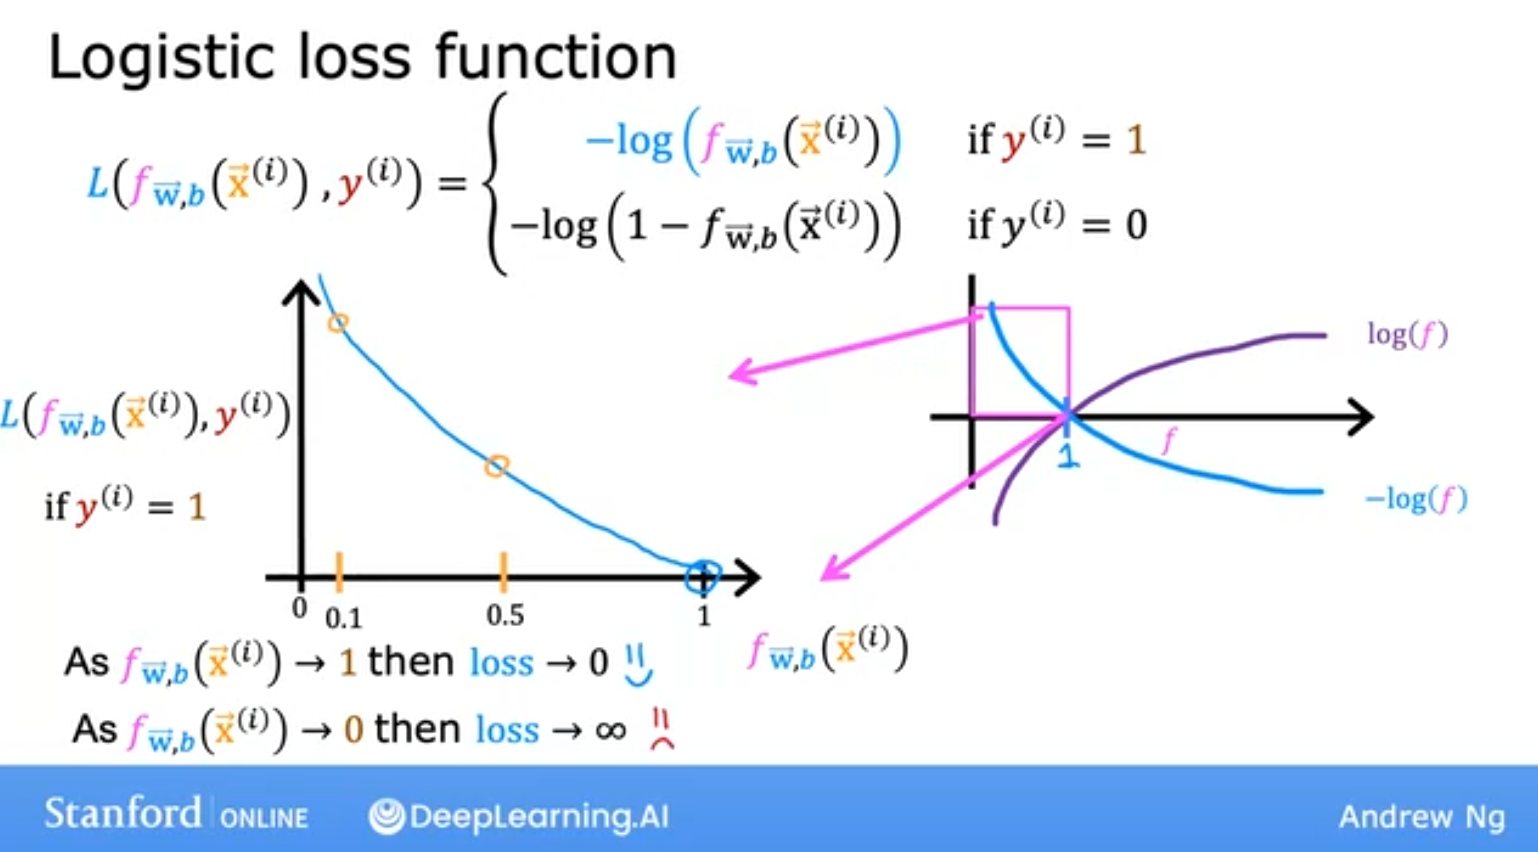

### Case 2: When the Actual Label Is 0

If:

$$
y=0
$$

The Loss Function is:

$$
\boxed{L(f(x),y)=-\log(1-f(x))}
$$

Here, $f(x)$ represents the predicted probability of class 1.

Therefore:

$$
1-f(x)
$$

represents the predicted probability of class 0.

When the actual label is 0, the model should predict a probability close to 0 for class 1.

#### Numerical Examples:

**Example A: Prediction = 0.1**

Given:

$$
y=0,\quad f(x)=0.1
$$

Apply the formula:

$$
L=-\log(1-0.1)
$$

$$
=-\log(0.9)
$$

$$
\boxed{L=0.1054}
$$

The loss is small because the model predicts only a 10% probability of class 1 and therefore a 90% probability of the correct class 0.

**Example B: Prediction = 0.5**

Given:

$$
y=0,\quad f(x)=0.5
$$

Apply the formula:

$$
L=-\log(1-0.5)
$$

$$
=-\log(0.5)
$$

$$
\boxed{L=0.6931}
$$

The loss is higher because the model is uncertain.

**Example C: Prediction = 0.9**

Given:

$$
y=0,\quad f(x)=0.9
$$

Apply the formula:

$$
L=-\log(1-0.9)
$$

$$
=-\log(0.1)
$$

$$
\boxed{L=2.3026}
$$

The loss is large because the actual label is 0, but the model predicts a 90% probability of class 1.

#### Summary for y = 0:

| Actual Label | Predicted Probability | Loss |
|---|---:|---:|
| 0 | 0.1 | 0.1054 |
| 0 | 0.5 | 0.6931 |
| 0 | 0.9 | 2.3026 |

**Important Observation:**

When the actual label is 0:

- If the prediction approaches 0, the loss approaches 0.
- If the prediction approaches 1, the loss approaches infinity.

Therefore, the loss function encourages the model to predict probabilities close to 0 when the actual label is 0.
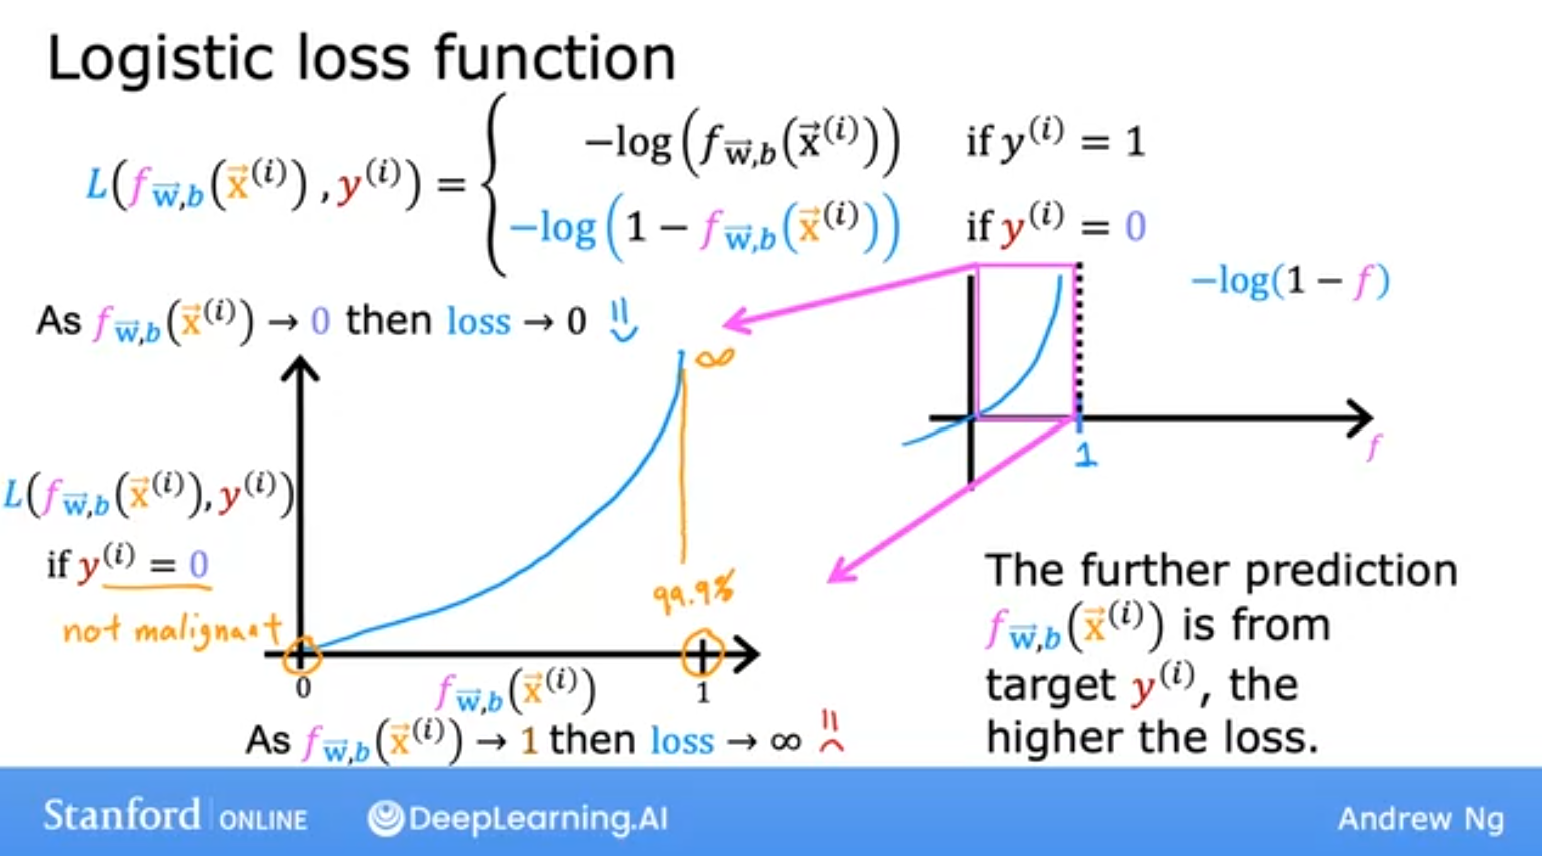

## 7. Complete Logistic Regression Loss Function:

We can combine both cases using a piecewise function.

$$
\boxed{
L(f(x),y)=
\begin{cases}
-\log(f(x)) & \text{if }y=1\\
-\log(1-f(x)) & \text{if }y=0
\end{cases}
}
$$

This is called the Logistic Loss Function or Log Loss.

### Why Does This Loss Function Make Sense?

When the actual label is 1:

- The loss is small when the predicted probability is close to 1.
- The loss becomes very large when the predicted probability is close to 0.

When the actual label is 0:

- The loss is small when the predicted probability is close to 0.
- The loss becomes very large when the predicted probability is close to 1.

This means the loss function strongly penalizes confident incorrect predictions.

### Comparison of Both Cases:

| Actual Label | Predicted Probability | Loss | Prediction Quality |
|---|---:|---:|---|
| 1 | 0.9 | 0.1054 | Good |
| 1 | 0.5 | 0.6931 | Uncertain |
| 1 | 0.1 | 2.3026 | Bad |
| 0 | 0.1 | 0.1054 | Good |
| 0 | 0.5 | 0.6931 | Uncertain |
| 0 | 0.9 | 2.3026 | Bad |

**Important:** The loss depends on both the predicted probability and the actual label.

## 8. Complete Numerical Example: Calculating Cost for Multiple Training Examples

Now let's calculate the overall Cost Function using the Logistic Loss Function.

Suppose we have three patients:

| Patient | Actual Label ($y$) | Predicted Probability ($f(x)$) |
|---|---:|---:|
| 1 | 1 | 0.9 |
| 2 | 0 | 0.2 |
| 3 | 1 | 0.7 |

### Step 1: Calculate Patient 1 Loss

Given:

$$
y^{(1)}=1,\quad f(x^{(1)})=0.9
$$

Since the actual label is 1, use:

$$
L_1=-\log(0.9)
$$

$$
\boxed{L_1=0.1054}
$$

### Step 2: Calculate Patient 2 Loss

Given:

$$
y^{(2)}=0,\quad f(x^{(2)})=0.2
$$

Since the actual label is 0, use:

$$
L_2=-\log(1-0.2)
$$

$$
=-\log(0.8)
$$

$$
\boxed{L_2=0.2231}
$$

### Step 3: Calculate Patient 3 Loss

Given:

$$
y^{(3)}=1,\quad f(x^{(3)})=0.7
$$

Since the actual label is 1, use:

$$
L_3=-\log(0.7)
$$

$$
\boxed{L_3=0.3567}
$$

### Step 4: Calculate the Overall Cost

The Cost Function is:

$$
\boxed{
J(\vec{w},b)=
\frac{1}{m}\sum_{i=1}^{m}L_i
}
$$

We have:

$$
m=3
$$

Substitute the losses:

$$
J=\frac{1}{3}(0.1054+0.2231+0.3567)
$$

$$
=\frac{0.6852}{3}
$$

$$
\boxed{J\approx0.2284}
$$

This is the average Logistic Regression loss for the three training examples.

## 9. Why Is Logistic Loss Better for Logistic Regression?

The Squared Error Cost Function combined with the sigmoid prediction model can produce a non-convex cost function.

A non-convex cost function may contain multiple local minima.

Gradient Descent can potentially get stuck in a local minimum instead of reaching the global minimum.

The Logistic Loss Function produces a convex cost function for standard Logistic Regression.

A convex function has an important property:

**Any local minimum is also a global minimum.**

This makes Gradient Descent more reliable for finding the global minimum when suitable optimization conditions are used.

### Comparison:

| Squared Error with Logistic Regression | Logistic Loss with Logistic Regression |
|---|---|
| Generally non-convex cost function. | Convex cost function for standard Logistic Regression. |
| Can contain multiple local minima. | Does not have separate local minima. |
| Not the preferred choice. | Designed for Logistic Regression. |

**Note:** The mathematical proof of convexity is beyond the scope of this course.

## 10. What Happens When the Predicted Probability Is Exactly 0 or 1?

Consider the loss function for $y=1$:

$$
L=-\log(f(x))
$$

When:

$$
f(x)\rightarrow0
$$

Then:

$$
-\log(f(x))\rightarrow+\infty
$$

Similarly, for $y=0$:

$$
L=-\log(1-f(x))
$$

When:

$$
f(x)\rightarrow1
$$

Then:

$$
-\log(1-f(x))\rightarrow+\infty
$$

Therefore, confidently predicting the wrong class produces an extremely large loss.

At the correct extremes:

- If $y=1$ and $f(x)=1$, loss is 0.
- If $y=0$ and $f(x)=0$, loss is 0.

These are mathematical limiting cases. Practical implementations handle numerical precision carefully.

## 11. Important Formulas Summary:

### Squared Error Loss:

$$
\boxed{
L(f(x),y)=\frac{1}{2}(f(x)-y)^2
}
$$

### Logistic Loss When y = 1:

$$
\boxed{L(f(x),y)=-\log(f(x))}
$$

### Logistic Loss When y = 0:

$$
\boxed{L(f(x),y)=-\log(1-f(x))}
$$

### Complete Logistic Regression Loss:

$$
\boxed{
L(f(x),y)=
\begin{cases}
-\log(f(x)) & y=1\\
-\log(1-f(x)) & y=0
\end{cases}
}
$$

### Logistic Regression Cost Function:

$$
\boxed{
J(\vec{w},b)=
\frac{1}{m}
\sum_{i=1}^{m}
L(f_{\vec{w},b}(\vec{x}^{(i)}),y^{(i)})
}
$$


A simplified version of the cost function is:

$$L(f_{\vec{w},b}(\vec{x}^{(i)}), y^{(i)}) = -y^{(i)}\log\left(f_{\vec{w},b}(\vec{x}^{(i)})\right) - (1 - y^{(i)})\log\left(1 - f_{\vec{w},b}(\vec{x}^{(i)})\right)$$


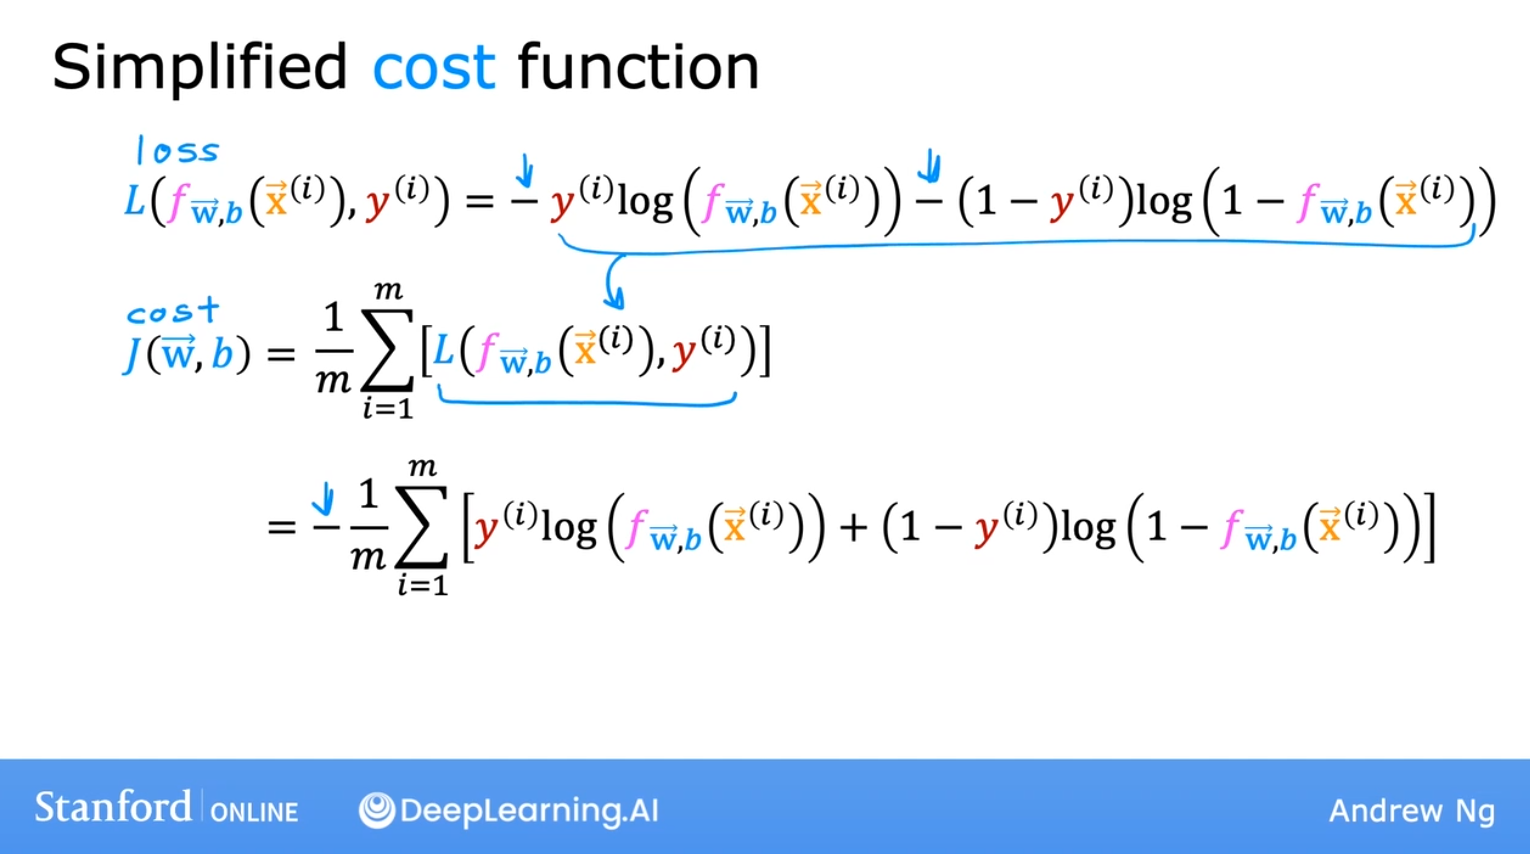